Lattices

In OpenMC, each lattice element has to be a universe. 

In [4]:
import openmc
import numpy as np

materials=openmc.Materials()
materials.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'
materials.export_to_xml()

# Surface definitions
s1 = openmc.ZCylinder(r=45,boundary_type='vacuum')
s10 = openmc.ZCylinder(r=8)
s301 = openmc.XPlane(10)
s302 = openmc.XPlane(-10)
s303 = openmc.YPlane(10)
s304 = openmc.YPlane(-10)

# OpenMC has universes that go into each lattice element.
def lat_u1():
    # Cells
    c2 = openmc.Cell(fill=None, region=(-s301 & +s302 & -s303 & +s304))
    u1 = openmc.Universe(cells=[c2]) 
    return u1

def lat_u2():
    # Cells
    c3 = openmc.Cell(fill=None,region=(-s10))
    c4 = openmc.Cell(fill=None,region=(~c3.region))
    
    u2 = openmc.Universe(cells=[c3,c4])
    return u2

lat_pattern = [
    [1,1,1,1,1],
    [1,2,2,2,1],
    [1,2,2,2,1],
    [1,2,2,2,1],
    [1,1,1,1,1],
]

pattern_map = {1: lat_u1(), 2: lat_u2()}

# Lattice definition
lattice = openmc.RectLattice()
lattice.lower_left = (-50,-50)
lattice.pitch = (20, 20)

lattice_universes = []
for row in lat_pattern:
    universe_row = [pattern_map[u] for u in row]
    lattice_universes.append(universe_row)
    
lattice.universes= lattice_universes


c5 = openmc.Cell(fill=None,region=+s1) 
lattice.outer=openmc.Universe(cells=[c5])
c1 = openmc.Cell(fill=lattice,region=-s1)

geometry=openmc.Geometry([c1,c5])

model = openmc.model.Model()
model.geometry=geometry
model.materials=materials

settings=openmc.Settings()
model.settings=settings
geometry.export_to_xml()
settings.export_to_xml()

In [2]:
w = 100
plots = openmc.Plots()


plot = openmc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = openmc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
plots.append(plot)

model.plots=plots
#model.export_to_xml()

Here's the output from openmc-plotter:

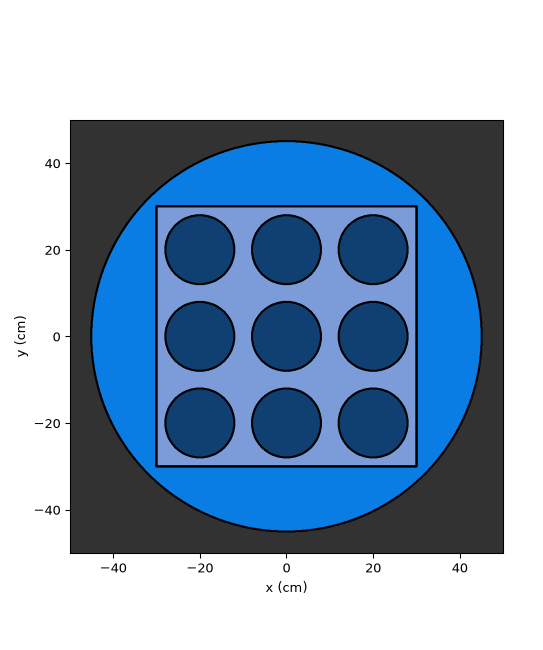

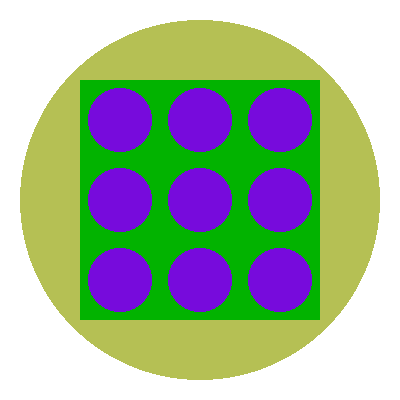

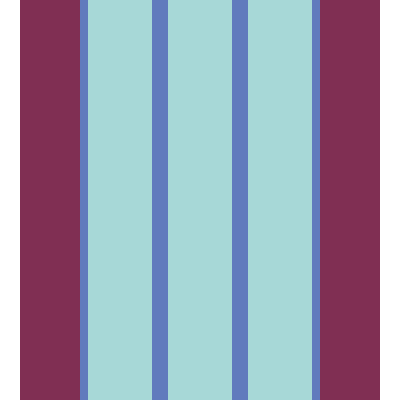

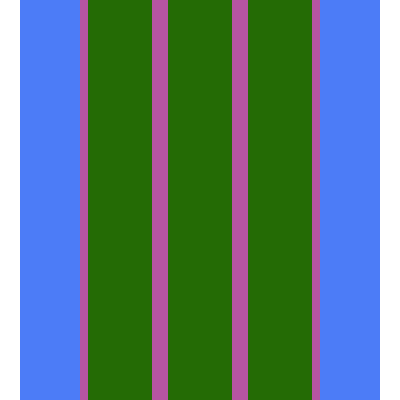

In [3]:
openmc.plot_inline(plots)